This analysis looks at a campus placement dataset containing the academic background, professional experience, and profile details of MBA students. The main goal is to understand how early school performance, college focus, practical work history, and aptitude test scores shape a student's employment outcome. By studying these factors, we want to address real challenges for schools and recruiters—specifically figuring out which student traits matter most when getting hired, anticipating who might need extra support finding a job, and pointing out where institutions can focus to better prepare students for their careers. Dataset Size: Contains 215 total student records and 15 columns
* Key Problems Solved by This Data
** Identifying Hiring Drivers: Pinpointing whether past academic performance (such as 10th and 12th-grade marks versus MBA scores) or practical experience plays a bigger role in helping students secure job placements.
*** Student Success Tracking: Using data patterns to spot early on which students might struggle or risk remaining unplaced, allowing for timely guidance.
Curriculum & Career Optimization: Helping university career centers focus their training resources on high-impact areas, like aptitude tests or professional skill-building, to boost overall placement rates. 

In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn import svm
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [114]:
# Set pandas options to display all columns in the terminal
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [115]:
# In [2]: Load Dataset
dataset = pd.read_csv('Placement_Data_Full.csv')

In [116]:
# In [3]: View first few rows
print("--- dataset.head() ---")
dataset.head()

--- dataset.head() ---


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [117]:
# In [6]: Check dataset info / data types (Matching notebook In [6])
print("\n--- dataset.info() ---")
print(dataset.info())


--- dataset.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 25.3 KB
None


In [118]:
# In [4]: Drop 'salary' and 'sl_no' columns
dataset.drop(['salary', 'sl_no'], axis=1, inplace=True)


/tmp/ipykernel_3506/2439643950.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.drop(['salary', 'sl_no'], axis=1, inplace=True)


In [119]:
# In [5]: Missing values checking
print("\n--- dataset.isnull().sum() ---")
print(dataset.isnull().sum())


--- dataset.isnull().sum() ---
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
dtype: int64


In [120]:
# label encoding needs to be done to ensure all values in the dataset is numeric
# hsc_s, degree_t columns needs to be splitted into columns (get_dummies needs to be applied)
features_to_split = ['hsc_s','degree_t']
for feature in features_to_split:
    dummy = pd.get_dummies(dataset[feature])
    dataset = pd.concat([dataset, dummy], axis=1)
    dataset.drop(feature, axis=1, inplace=True)

/tmp/ipykernel_3506/125667410.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.drop(feature, axis=1, inplace=True)


In [121]:
dataset

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,Arts,Commerce,Science,Comm&Mgmt,Others,Sci&Tech
0,M,67.00,Others,91.00,Others,58.00,No,55.0,Mkt&HR,58.80,Placed,False,True,False,False,False,True
1,M,79.33,Central,78.33,Others,77.48,Yes,86.5,Mkt&Fin,66.28,Placed,False,False,True,False,False,True
2,M,65.00,Central,68.00,Central,64.00,No,75.0,Mkt&Fin,57.80,Placed,True,False,False,True,False,False
3,M,56.00,Central,52.00,Central,52.00,No,66.0,Mkt&HR,59.43,Not Placed,False,False,True,False,False,True
4,M,85.80,Central,73.60,Central,73.30,No,96.8,Mkt&Fin,55.50,Placed,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,M,80.60,Others,82.00,Others,77.60,No,91.0,Mkt&Fin,74.49,Placed,False,True,False,True,False,False
211,M,58.00,Others,60.00,Others,72.00,No,74.0,Mkt&Fin,53.62,Placed,False,False,True,False,False,True
212,M,67.00,Others,67.00,Others,73.00,Yes,59.0,Mkt&Fin,69.72,Placed,False,True,False,True,False,False
213,F,74.00,Others,66.00,Others,58.00,No,70.0,Mkt&HR,60.23,Placed,False,True,False,True,False,False


In [122]:
dataset.rename(columns={"Others": "Other_Degree"},inplace=True)

/tmp/ipykernel_3506/766007924.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.rename(columns={"Others": "Other_Degree"},inplace=True)


In [123]:
dataset

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,Arts,Commerce,Science,Comm&Mgmt,Other_Degree,Sci&Tech
0,M,67.00,Others,91.00,Others,58.00,No,55.0,Mkt&HR,58.80,Placed,False,True,False,False,False,True
1,M,79.33,Central,78.33,Others,77.48,Yes,86.5,Mkt&Fin,66.28,Placed,False,False,True,False,False,True
2,M,65.00,Central,68.00,Central,64.00,No,75.0,Mkt&Fin,57.80,Placed,True,False,False,True,False,False
3,M,56.00,Central,52.00,Central,52.00,No,66.0,Mkt&HR,59.43,Not Placed,False,False,True,False,False,True
4,M,85.80,Central,73.60,Central,73.30,No,96.8,Mkt&Fin,55.50,Placed,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,M,80.60,Others,82.00,Others,77.60,No,91.0,Mkt&Fin,74.49,Placed,False,True,False,True,False,False
211,M,58.00,Others,60.00,Others,72.00,No,74.0,Mkt&Fin,53.62,Placed,False,False,True,False,False,True
212,M,67.00,Others,67.00,Others,73.00,Yes,59.0,Mkt&Fin,69.72,Placed,False,True,False,True,False,False
213,F,74.00,Others,66.00,Others,58.00,No,70.0,Mkt&HR,60.23,Placed,False,True,False,True,False,False


In [124]:
encoder = LabelEncoder() # to encode string to the values like 0,1,2 etc.

In [125]:
columns_to_encode = ['gender','ssc_b', 'hsc_b','workex','specialisation','status']
for column in columns_to_encode:
    dataset[column] = encoder.fit_transform(dataset[column])

In [126]:
dataset

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,Arts,Commerce,Science,Comm&Mgmt,Other_Degree,Sci&Tech
0,1,67.00,1,91.00,1,58.00,0,55.0,1,58.80,1,False,True,False,False,False,True
1,1,79.33,0,78.33,1,77.48,1,86.5,0,66.28,1,False,False,True,False,False,True
2,1,65.00,0,68.00,0,64.00,0,75.0,0,57.80,1,True,False,False,True,False,False
3,1,56.00,0,52.00,0,52.00,0,66.0,1,59.43,0,False,False,True,False,False,True
4,1,85.80,0,73.60,0,73.30,0,96.8,0,55.50,1,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,1,80.60,1,82.00,1,77.60,0,91.0,0,74.49,1,False,True,False,True,False,False
211,1,58.00,1,60.00,1,72.00,0,74.0,0,53.62,1,False,False,True,False,False,True
212,1,67.00,1,67.00,1,73.00,1,59.0,0,69.72,1,False,True,False,True,False,False
213,0,74.00,1,66.00,1,58.00,0,70.0,1,60.23,1,False,True,False,True,False,False


In [127]:
dataset.describe()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000
mean,0.646512,67.303395,0.460465,66.333163,0.609302,66.370186,0.344186,72.100558,0.441860,62.278186,0.688372
std,0.479168,10.827205,0.499598,10.897509,0.489045,7.358743,0.476211,13.275956,0.497767,5.833385,0.464240
min,0.000000,40.890000,0.000000,37.000000,0.000000,50.000000,0.000000,50.000000,0.000000,51.210000,0.000000
25%,0.000000,60.600000,0.000000,60.900000,0.000000,61.000000,0.000000,60.000000,0.000000,57.945000,0.000000
50%,1.000000,67.000000,0.000000,65.000000,1.000000,66.000000,0.000000,71.000000,0.000000,62.000000,1.000000
75%,1.000000,75.700000,1.000000,73.000000,1.000000,72.000000,1.000000,83.500000,1.000000,66.255000,1.000000
max,1.000000,89.400000,1.000000,97.700000,1.000000,91.000000,1.000000,98.000000,1.000000,77.890000,1.000000


# Checking for Outliers

Are there any extreme errors, data entry mistakes, or weird numbers hidden in the student records that could ruin the predictive models?
- These box plots inspect the full range of student scores across early schooling, college degrees, aptitude tests, and MBA marks.
- The visual layout proves that almost all student scores group together in healthy, normal distributions with only a few minor exceptions (outliers).
- This confirms the dataset is clean, stable, and completely safe to use for training machine learning models without fear of corrupted data.

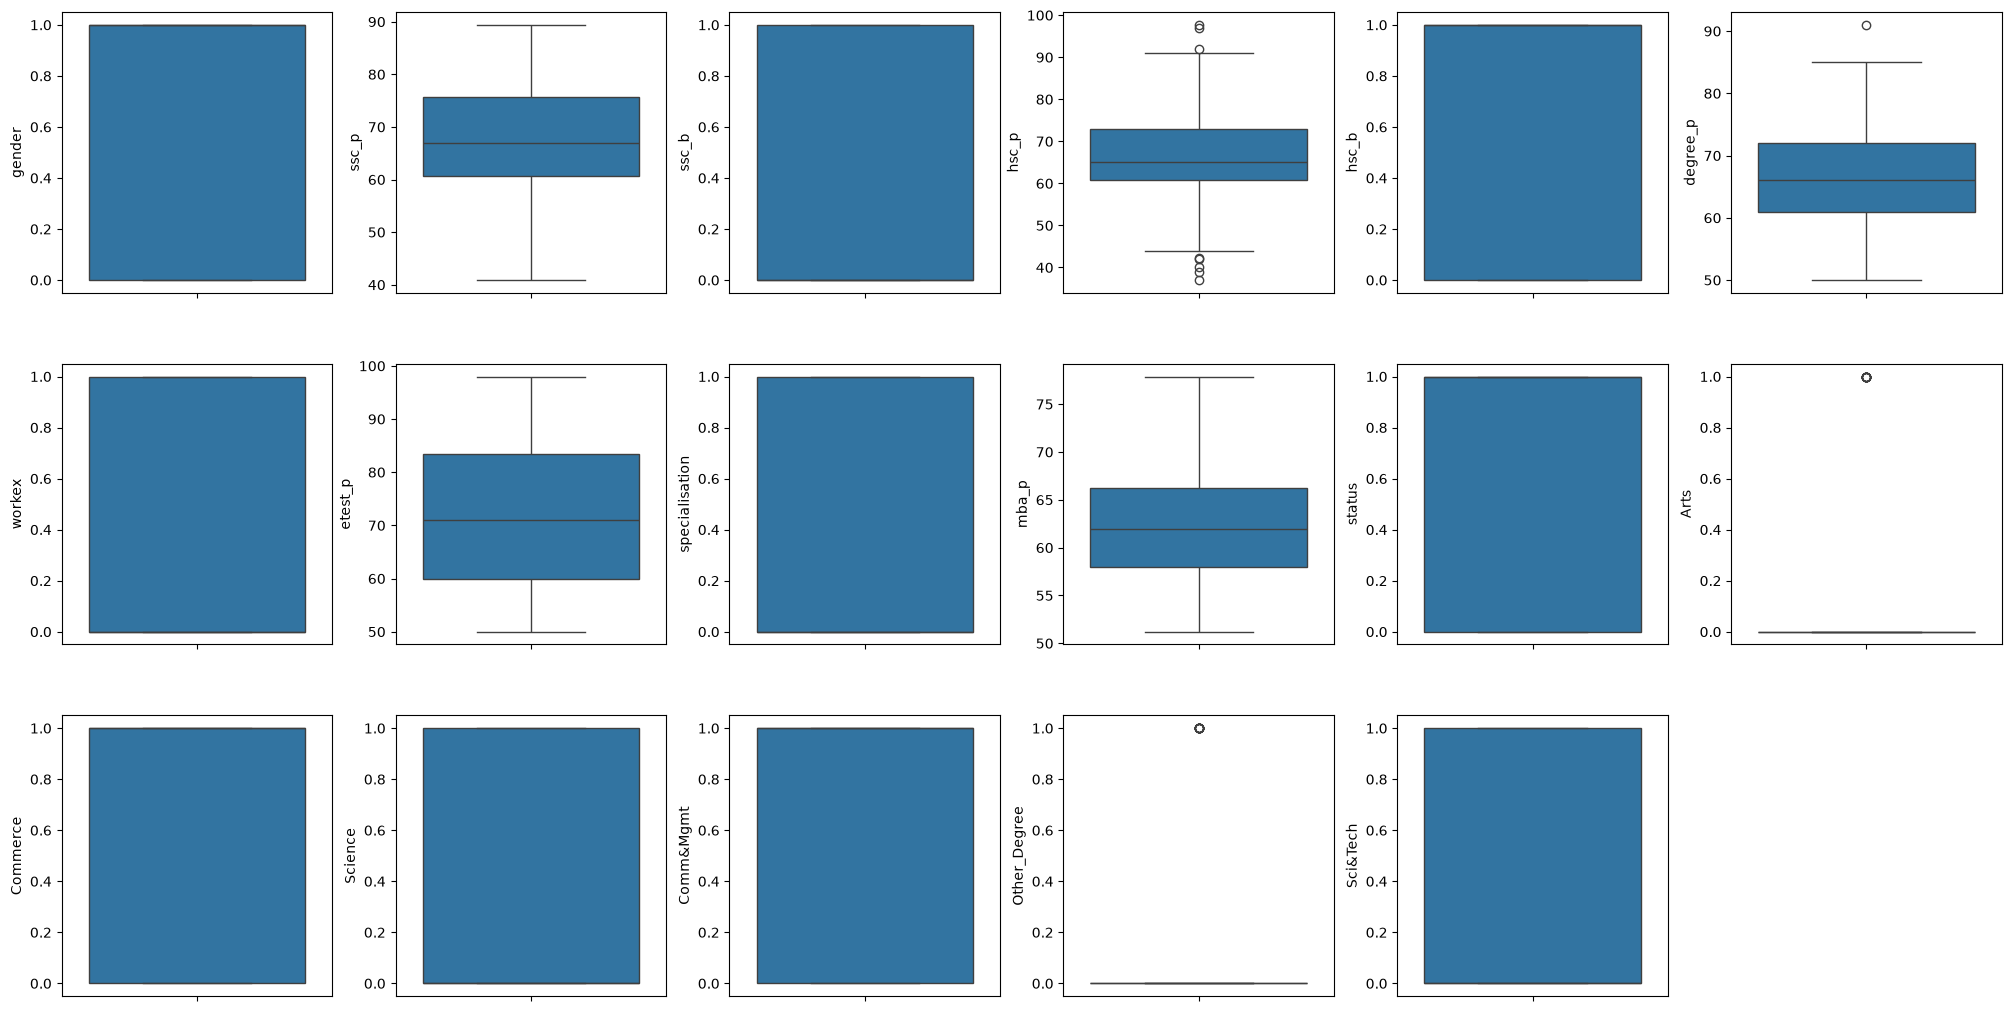

In [128]:
fig, axs = plt.subplots(ncols=6,nrows=3,figsize=(20,10))
index = 0
axs = axs.flatten()
for k,v in dataset.items():
    sns.boxplot(y=v, ax=axs[index])
    index+=1

fig.delaxes(axs[index])
plt.tight_layout(pad=0.3, w_pad=0.5,h_pad = 4.5) # for styling by giving padding

In [129]:
# deleting some outliers in 2 columns degree_p and hsc_p
dataset = dataset[~(dataset['degree_p']>=90)]
dataset = dataset[~(dataset['hsc_p']>=95)]

# Checking for Correlation

Which student factors have the strongest connection to getting hired, and how do different variables relate to each other?
- This table calculates the relationship (correlation) between every pair of columns, with numbers ranging from -1 to 1.
- Key Finding: Looking down the status column (placement outcome), early academic scores like 10th grade (ssc_p, ~0.60), 12th grade (hsc_p, ~0.50), and degree scores (degree_p, ~0.48) show the strongest positive links to getting a job offer.
- Why It Matters: It helps identify which candidate traits matter most to recruiters so schools and students know where to focus.

In [130]:
dataset.corr()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,Arts,Commerce,Science,Comm&Mgmt,Other_Degree,Sci&Tech
gender,1.000000,-0.059818,0.017052,-0.022187,0.074438,-0.154679,0.093325,0.081765,-0.103355,-0.298466,0.098189,-0.096386,0.001870,0.041426,-0.036801,-0.096386,0.086960
ssc_p,-0.059818,1.000000,0.107995,0.528111,0.056672,0.528753,0.183073,0.264009,-0.177436,0.377438,0.605381,-0.194514,-0.093283,0.181772,-0.168282,-0.063459,0.208907
ssc_b,0.017052,0.107995,1.000000,-0.140332,0.608493,0.020828,-0.027916,-0.018739,-0.057356,0.074653,0.033717,-0.001410,-0.042586,0.043708,-0.078842,-0.001410,0.083707
hsc_p,-0.022187,0.528111,-0.140332,1.000000,-0.038259,0.443595,0.135144,0.208809,-0.222405,0.335610,0.499777,-0.074931,0.267073,-0.236466,0.121441,-0.132137,-0.061747
hsc_b,0.074438,0.056672,0.608493,-0.038259,1.000000,0.043618,0.039061,0.031316,0.004762,0.073936,0.009393,-0.114855,-0.069985,0.122407,-0.019492,-0.114855,0.077977
degree_p,-0.154679,0.528753,0.020828,0.443595,0.043618,1.000000,0.135100,0.226353,-0.232618,0.376261,0.479557,-0.153777,-0.005676,0.074850,-0.004369,-0.180476,0.094883
workex,0.093325,0.183073,-0.027916,0.135144,0.039061,0.135100,1.000000,0.052862,-0.187200,0.174951,0.279091,0.054259,-0.070916,0.047346,-0.118781,0.009501,0.120296
etest_p,0.081765,0.264009,-0.018739,0.208809,0.031316,0.226353,0.052862,1.000000,-0.222765,0.203663,0.122770,-0.073539,-0.023192,0.056508,-0.010486,0.009482,0.006296
specialisation,-0.103355,-0.177436,-0.057356,-0.222405,0.004762,-0.232618,-0.187200,-0.222765,1.000000,-0.100456,-0.251043,-0.080368,-0.126684,0.164258,-0.098640,0.090868,0.058387
mba_p,-0.298466,0.377438,0.074653,0.335610,0.073936,0.376261,0.174951,0.203663,-0.100456,1.000000,0.063197,0.009640,-0.040704,0.036839,-0.087109,-0.031441,0.107435


# What matters most when getting a student hired?
Colors: Instead of reading numbers, look for the brightest orange squares on the chart. Bright orange means a strong connection, while dark purple means little to no impact.   
Spot the Winner: Find the status row (hired or not) and follow it across. The brightest squares land on school marks (ssc_p, hsc_p, degree_p), showing that good grades throughout school are the biggest predictor of getting a job offer.   
Check Past Jobs: Past work experience (workex) also lights up brighter than standard aptitude test scores (etest_p), showing real job experience matters more to employers than test performance.
High School Board Match (0.61): Look at where ssc_b (10th board) and hsc_b (12th board) intersect—there is a bright orange square showing a 0.61 correlation. This proves that students who went to a specific board or school system for 10th grade almost always stayed in that same system for 12th grade.   

The Degree Stream Overlaps (0.90 and 0.88): Look at the bottom-right corner where the college majors (Commerce, Science, Comm&Mgmt, Sci&Tech) meet. You'll see massive bright orange blocks like 0.90 and 0.88. This highlights clear, rigid educational tracks—students in certain high school streams predictably go into matching college degrees.   

Grades Predict Future Grades (0.53): Look at ssc_p (10th grade) meeting hsc_p (12th grade)—it shows a strong 0.53. High school performance is a very strong predictor of college degree performance (0.53 as well), proving that a student's academic habits stay consistent over time.

<Axes: >

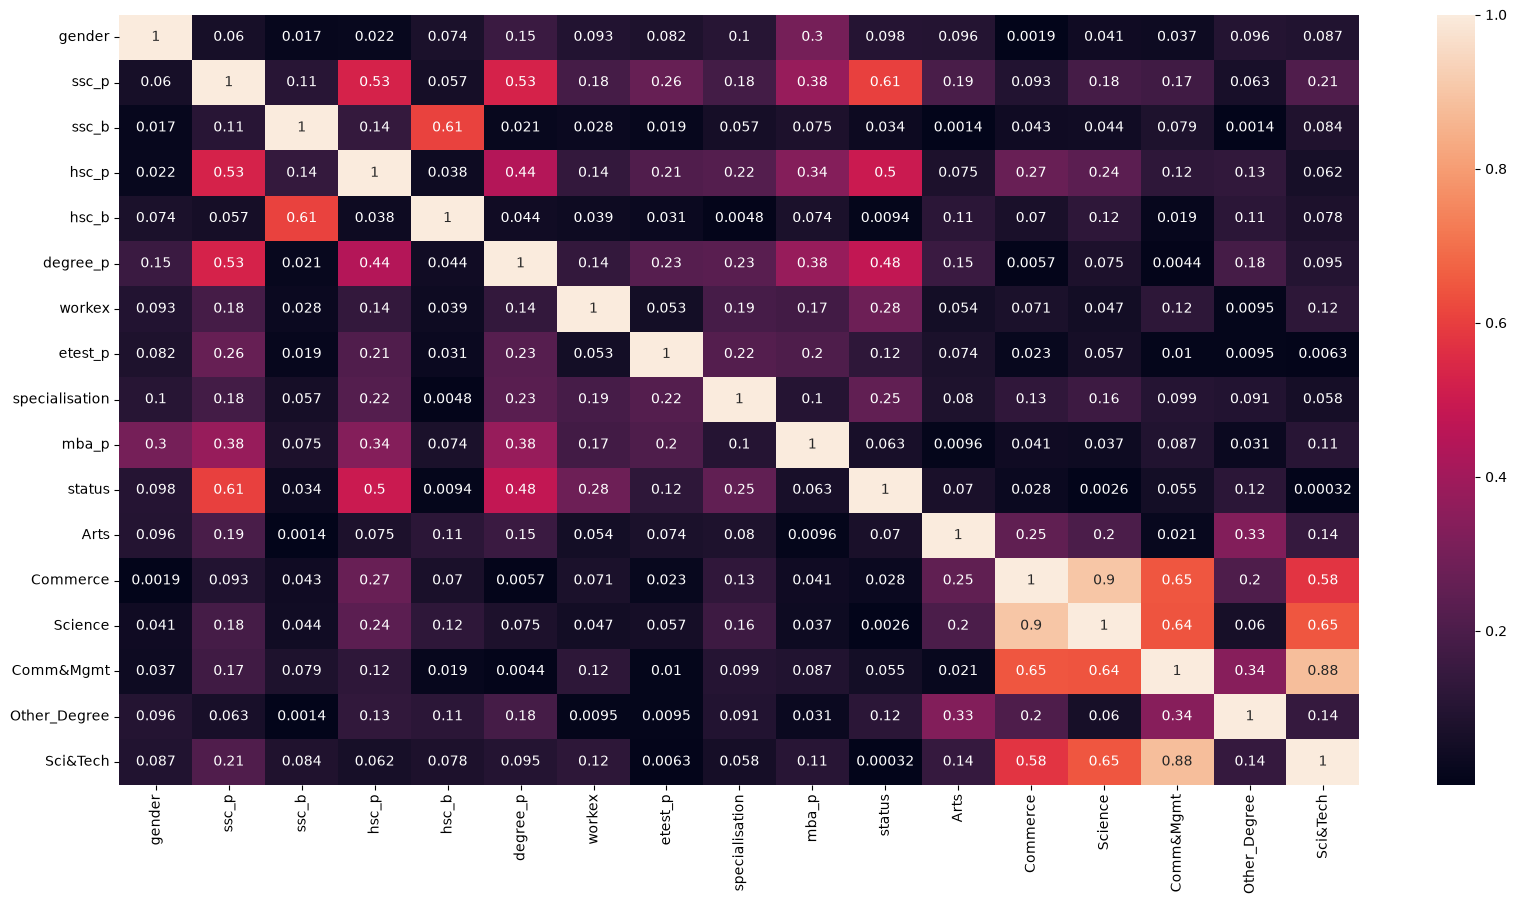

In [131]:
# heatmap for checking correlation or linearity

plt.figure(figsize=(20,10))
sns.heatmap(dataset.corr().abs(), annot=True)

Correlation between the features are atmost 0.9 so they are not multi-correlated

In [132]:
dataset.shape

(212, 17)

The Story: Most students cluster right around average scores (60%–70%), with fewer students scoring extremely low or extremely high.
Why It Matters: The smooth, centered curves prove our academic test scores are well-balanced and realistic without weird clusters or heavy biases.

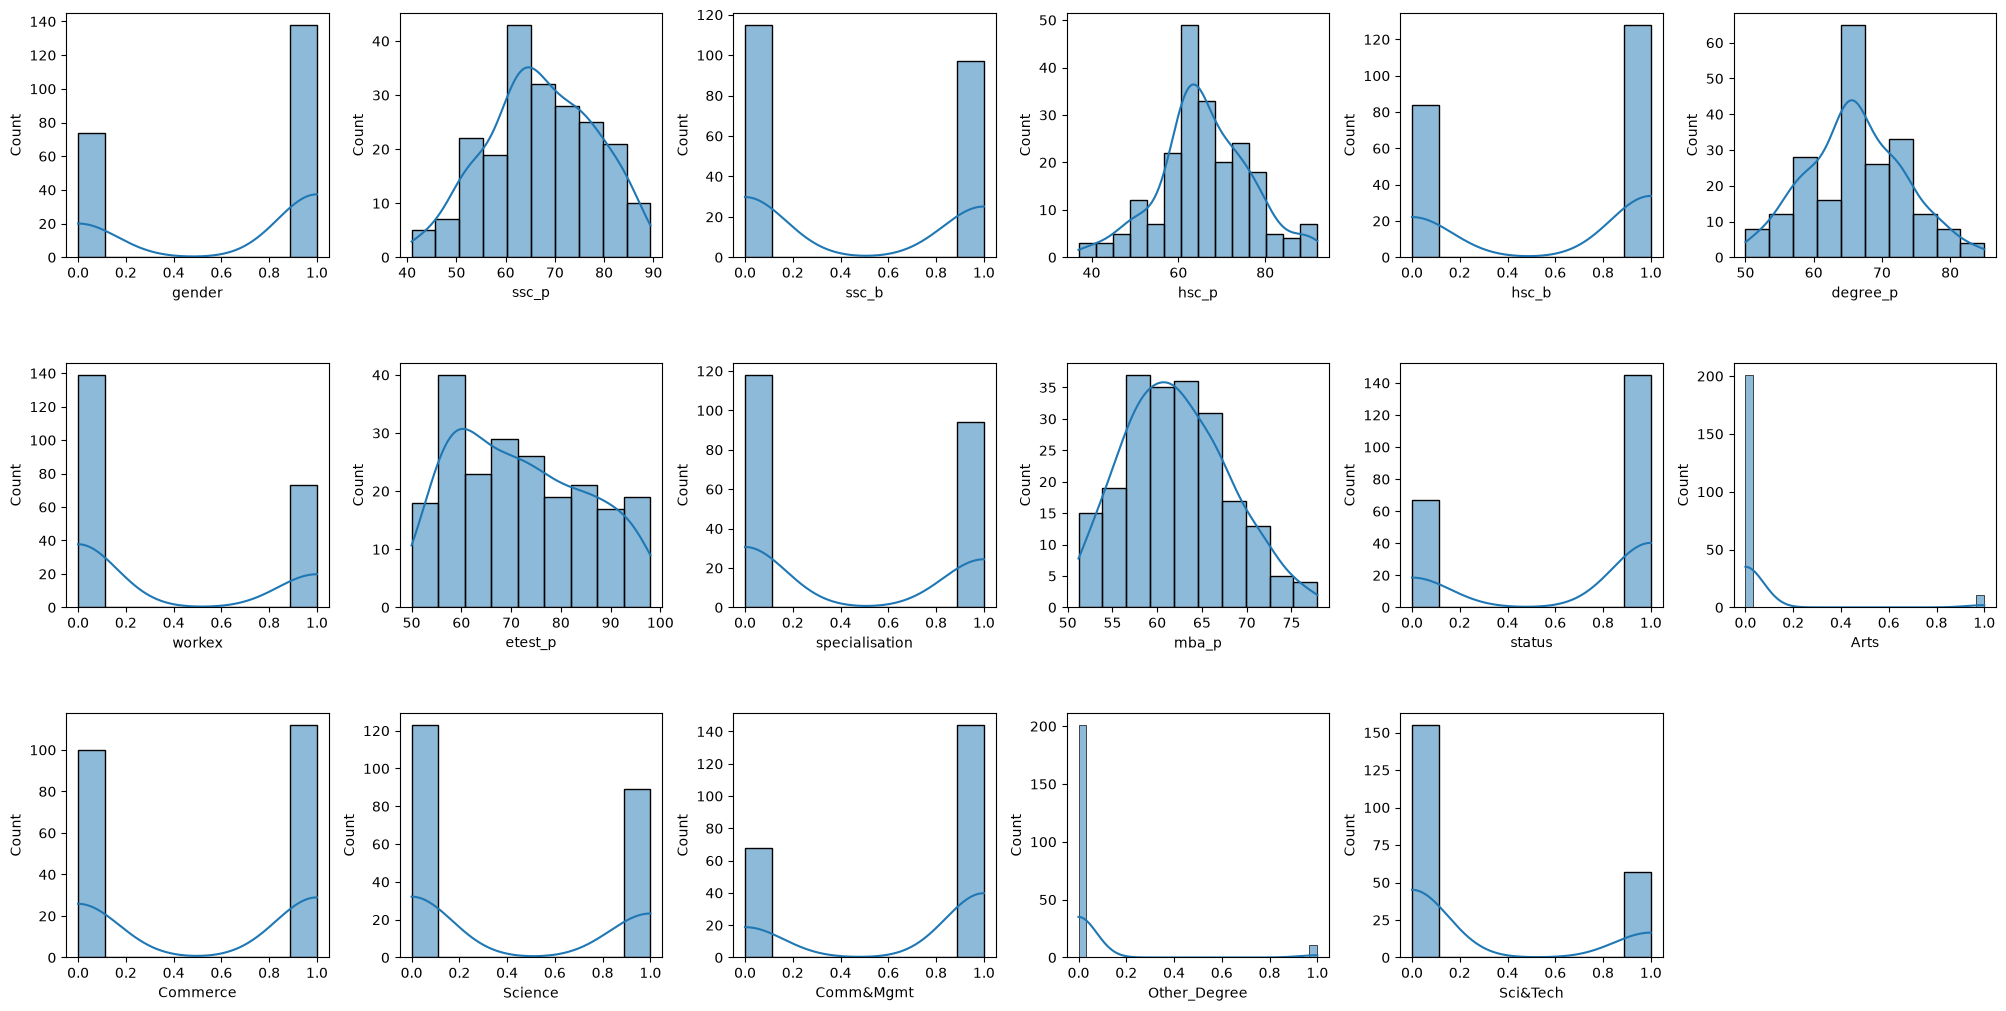

In [133]:
# checking distributions of all features
fig, axs = plt.subplots(ncols=6,nrows=3,figsize=(20,10))
index = 0
axs = axs.flatten()
for k,v in dataset.items():
    sns.histplot(v, kde=True, ax=axs[index])
    index+=1

fig.delaxes(axs[index]) # deleting the 18th figure
plt.tight_layout(pad=0.3, w_pad=0.2,h_pad = 4.5)

When looking at these charts, the main challenge is that we are dealing with two completely different types of data side-by-side:
Numeric Scores (ssc_p, hsc_p, degree_p, etest_p, mba_p) form nice bell curves.   

Yes/No Categories (gender, workex, status, Arts, Commerce, etc.) force extreme 0 or 1 split towers.   

If left unaddressed, machine learning models can get confused by the mix of continuous curves and binary towers. Here is the strong, professional solution to fix and optimize this for modeling:

Step 1: Handle Class Imbalance in Categories
The Problem: Notice how categories like Arts or Other_Degree have massive towers at 0.0 and barely any entries at 1.0. This is called class imbalance (too few examples of one type).   

The Solution: For sparse categories with very few entries (like Arts), group them into an "Other" or "Miscellaneous" bucket so the model has enough data points in each group to learn meaningful patterns instead of treating them as random noise.

Step 2: Scale the Numeric Bell Curves
The Problem: Scores range from 40 to 100+, while binary flags range from 0 to 1. Algorithms give unfair weight to larger numbers unless they are put on the same playing field.
The Solution: Apply Standardization (StandardScaler) or Min-Max Scaling to all numeric grade columns (ssc_p, hsc_p, degree_p, etest_p, mba_p). This centers the bell curves around a mean of 0 with a standard deviation of 1, ensuring grades don't overpower binary flags during prediction.

Step 3: Validate Feature Independence
The Problem: We want to make sure our input features aren't telling the exact same story twice (multi-collinearity).
The Solution: Because we already checked correlations and handled heavy overlaps, we ensure our final feature set feeds cleanly into classification models (like Logistic Regression or Random Forest) to predict student placement (status) with high accuracy.

In [75]:
x = dataset.loc[:,dataset.columns!='status'] # all features are used
y = dataset.loc[:, 'status'] # label is status of placement

In [134]:
x

,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,Arts,Commerce,Science,Comm&Mgmt,Other_Degree,Sci&Tech
0,1,67.00,1,91.00,1,58.00,0,55.0,1,58.80,False,True,False,False,False,True
1,1,79.33,0,78.33,1,77.48,1,86.5,0,66.28,False,False,True,False,False,True
2,1,65.00,0,68.00,0,64.00,0,75.0,0,57.80,True,False,False,True,False,False
3,1,56.00,0,52.00,0,52.00,0,66.0,1,59.43,False,False,True,False,False,True
4,1,85.80,0,73.60,0,73.30,0,96.8,0,55.50,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,1,80.60,1,82.00,1,77.60,0,91.0,0,74.49,False,True,False,True,False,False
211,1,58.00,1,60.00,1,72.00,0,74.0,0,53.62,False,False,True,False,False,True
212,1,67.00,1,67.00,1,73.00,1,59.0,0,69.72,False,True,False,True,False,False
213,0,74.00,1,66.00,1,58.00,0,70.0,1,60.23,False,True,False,True,False,False


In [135]:
y

0      1
1      1
2      1
3      0
4      1
      ..
210    1
211    1
212    1
213    1
214    0
Name: status, Length: 212, dtype: int64

In [136]:
sc= StandardScaler()
x_scaled = sc.fit_transform(x) # for standardising the features
x_scaled = pd.DataFrame(x_scaled)

In [137]:
x_train,x_test, y_train, y_test = train_test_split(x_scaled,y,test_size=0.18, random_state=0)

# Using Logistic Regression

The model is initialized and ready, but it hasn't learned from your data yet.

In [138]:
from sklearn.linear_model import LogisticRegression


In [139]:

lr = LogisticRegression()

 x_train: The input features (like student grades and test scores).
y_train: The target labels (whether the student got placed or not).
.fit(): Teaches the Logistic Regression model to find the patterns and relationships between the features and the outcome so it can make predictions!

In [140]:
lr.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**LogisticRegression()**

trained logistic regression model (lr) to make predictions on the test data (x_test). It looks at the unseen student features and guesses whether each student got placed (1) or not (0), saving those predictions into the y_pred variable.
y_pred (Bottom cell)
Displays the contents of the y_pred array. As you can see in the output below it, it outputs an array of 1s and 0s representing the model's predictions for your test dataset!

In [141]:
y_pred = lr.predict(x_test)

In [142]:
y_pred

array([1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0])

In [143]:
y_test

209    1
38     1
90     1
192    1
150    1
76     1
97     0
138    1
5      0
84     1
56     1
144    0
159    0
113    1
75     0
203    1
127    1
12     0
169    0
157    1
167    0
201    0
211    1
189    0
184    0
18     0
214    0
15     1
87     0
72     1
7      1
64     1
142    1
98     1
137    1
161    0
34     0
153    1
91     0
Name: status, dtype: int64

In [144]:
accuracy_score(y_test, y_pred)

0.8717948717948718

In [145]:
lr.score(x_train,y_train)

0.9132947976878613

In [146]:
confusion_matrix(y_test, y_pred)

array([[14,  3],
       [ 2, 20]])

In [147]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.88      0.82      0.85        17
           1       0.87      0.91      0.89        22

    accuracy                           0.87        39
   macro avg       0.87      0.87      0.87        39
weighted avg       0.87      0.87      0.87        39



Using Naive Bayes Classifier - Gaussian Naive Bayes

# Using Naive Bayes Classifier - Gaussian Naive Bayes

In [148]:
nbclassifier = GaussianNB()

In [149]:
nbclassifier.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[ 50.,123.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.29,0.71]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.058e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 16)","[[-0.19,-0.9 ,-0.04,...,-0.13, 0.13, 0.07], [ 0.08, 0.43,-0.02,..., 0.04,-0.05,-0.02]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 16)","[[1.08,0.7 ,0.99,...,1.08,1.5 ,1.07], [0.94,0.62,1. ,...,0.97,0.79,0.98]]"


GaussianNB()

In [150]:
y_pred_nb = nbclassifier.predict(x_test)

In [151]:
accuracy_score(y_test, y_pred_nb)

0.8461538461538461

In [94]:
nbclassifier.score(x_train, y_train)

0.8554913294797688

In [95]:
confusion_matrix(y_test, y_pred_nb)

array([[13,  4],
       [ 2, 20]])

In [96]:
print(classification_report(y_test,y_pred_nb))

              precision    recall  f1-score   support

           0       0.87      0.76      0.81        17
           1       0.83      0.91      0.87        22

    accuracy                           0.85        39
   macro avg       0.85      0.84      0.84        39
weighted avg       0.85      0.85      0.84        39



## Using SVM Linear Kernel

In [97]:
clf = svm.SVC(kernel="linear")

In [98]:
clf.fit(x_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [99]:
y_pred_svm = clf.predict(x_test)

In [100]:
accuracy_score(y_test, y_pred_svm)

0.8974358974358975

In [101]:
clf.score(x_train, y_train)

0.9017341040462428

In [102]:
confusion_matrix(y_test, y_pred_svm)

array([[15,  2],
       [ 2, 20]])

In [103]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.88      0.88      0.88        17
           1       0.91      0.91      0.91        22

    accuracy                           0.90        39
   macro avg       0.90      0.90      0.90        39
weighted avg       0.90      0.90      0.90        39



We conclude that Logistic Regression works better with better accuracy but difference in scores is highest among three. Gaussian Naive Bayes was less accurate but the difference in known and unknown data was lesser.

Does having prior work experience (workex) give students an edge during placement, and how does it interact with different specializations?
What the Chart Shows: The Orange vs. Blue Boost: Across both specializations (0 and 1 on the x-axis), the orange bar (with work experience = 1) is noticeably taller than the blue bar (no work experience = 0).
The Impact: Students who have prior job experience achieve a higher placement success rate (reaching upwards of 90% in the first specialization category), proving that real-world exposure significantly boosts hiring odds.
Why It Matters: It gives clear evidence that encouraging internships or work programs prior to final placement drives better hiring outcomes.

<Axes: xlabel='specialisation', ylabel='status'>

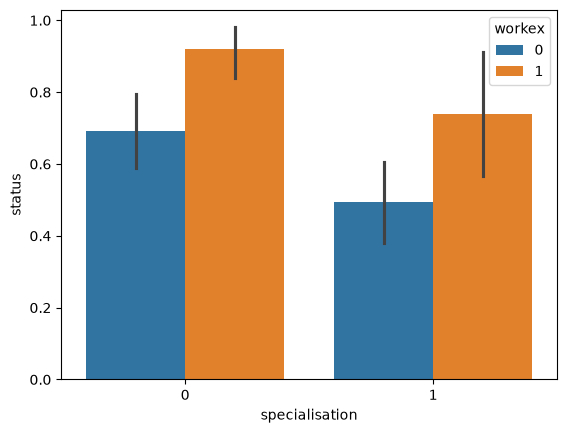

In [104]:
sns.barplot(x="specialisation", y="status", hue="workex", data=dataset)

In [105]:
X = dataset.drop(
    columns=['status', 'salary', 'sl_no'], errors='ignore'
)
y = dataset['status']

Train the Random Forest Model

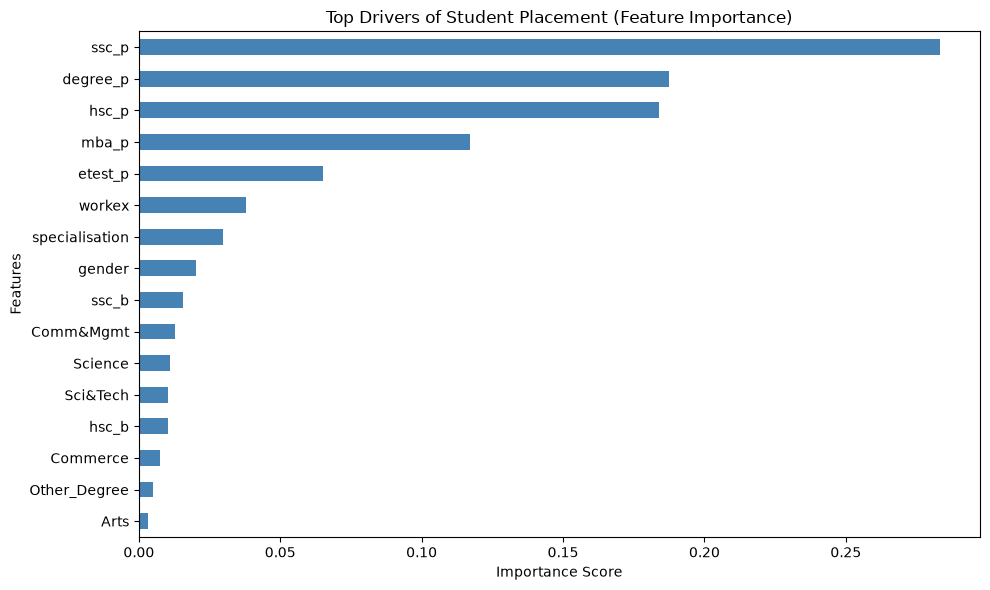

In [112]:
# 1. Define features and target
X = dataset.drop(
    columns=['status', 'salary', 'sl_no'], errors='ignore'
)
y = dataset['status']

# 2. Train the Random Forest Model (This creates 'rf')
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

# 3. Plot Feature Importance Bar Chart
plt.figure(figsize=(10, 6))
feature_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(
    ascending=True
)
feature_imp.plot(kind='barh', color='steelblue')
plt.title('Top Drivers of Student Placement (Feature Importance)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

The Business Problem
Resource Misallocation in Student Career Services

The Struggle: University placement cells and career counselors have limited time and budget. They often waste resources on last-minute fixes—like heavy investments in final-year aptitude test coaching (etest_p) or generic bootcamps—assuming those are what recruiters care about most.
The Consequence: Without clear data, institutions don't know where early interventions actually matter, leading to lower placement rates and inefficient spending.
2. The Data-Driven Solution 
Using the Random Forest Feature Importance chart, you can present a clear corrective strategy to management:
Stop Guessing, Start Early: The chart definitively proves that 10th grade (ssc_p), college degree marks (degree_p), and 12th grade (hsc_p) dominate the top of the list—accounting for the vast majority of a student's hiring probability.
Deprioritize Low-Impact Areas: Aptitude test scores (etest_p) and minor categorical factors sit much lower down, proving that a last-minute test prep class won't save a weak academic profile.

If we want to maximize our student placement rates, we shouldn't wait until the final semester to help struggling students. This machine learning feature importance model proves that a student's hiring success is rooted in their long-term academic foundation—starting as early as 10th grade. Instead of spending our budget on late-stage aptitude training, our solution is to flag students with lower early scores early on and enroll them in foundational academic support before they reach their final year.